In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from descriptive_functions import get_data

In [2]:
FILENAME = "../data/lung_cancer_dataset.csv"

df = get_data(FILENAME)
print(df.head())


  Patient_ID  Diagnosis_Year Diagnosis_Date       WHO_Region    Country  Age  \
0    LC-0001            2020     2020-11-04  Western Pacific      China   46   
1    LC-0002            2021     2021-12-09         Americas     Mexico   71   
2    LC-0003            2017     2017-04-05  Western Pacific      Japan   53   
3    LC-0004            2018     2018-11-24  Western Pacific  Singapore   55   
4    LC-0005            2024     2024-02-19  Western Pacific   Malaysia   54   

  Age_Group  Gender  Smoking_Status  Cigarettes_Per_Day  ...  Symptom_Count  \
0     40-49  Female  Current Smoker                  28  ...              5   
1     70-79    Male   Former Smoker                   5  ...              5   
2     50-59  Female    Never Smoked                   0  ...              3   
3     50-59    Male  Current Smoker                  21  ...              6   
4     50-59    Male    Never Smoked                   0  ...              5   

   Cancer_Type   NSCLC_Subtype Cancer_Stage 

In [15]:
# PATIENT COUNTS 
patient_df = df.filter(items=["Gender", "Age_Group", "Country", "Family_History"])
print(patient_df.head())

# returns the counts of each unique value in a given category
def get_category_count(category, data):
    return data[category].value_counts(dropna=True)

print(get_category_count("Gender", patient_df),"\n")
print(get_category_count("Age_Group", patient_df),"\n")
print(get_category_count("Country", patient_df),"\n")
print(get_category_count("Family_History", patient_df),"\n")

   Gender Age_Group    Country Family_History
0  Female     40-49      China             No
1    Male     70-79     Mexico             No
2  Female     50-59      Japan             No
3    Male     50-59  Singapore            Yes
4    Male     50-59   Malaysia             No
Gender
Male      1248
Female     752
Name: count, dtype: int64 

Age_Group
50-59    657
60-69    655
70-79    354
40-49    230
80-89     68
30-39     36
Name: count, dtype: int64 

Country
Japan           74
Malaysia        72
New Zealand     71
China           67
Vietnam         62
Philippines     62
Singapore       60
Australia       58
Mongolia        54
Sweden          52
South Korea     51
Germany         48
Russia          45
Brazil          42
Netherlands     42
Cuba            42
Bangladesh      42
Spain           41
Italy           40
Argentina       40
Colombia        37
France          36
Poland          35
Turkey          35
Canada          35
Maldives        33
Peru            33
Mexico          32
Nep

# Patient Descriptive Statistics Visuals

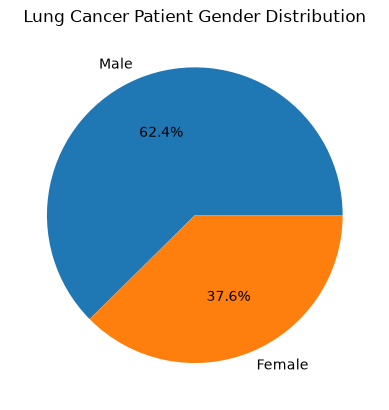

In [ ]:
# Pie Chart (Gender)
gender_count = get_category_count("Gender", patient_df)
plt.pie(gender_count, 
        labels=gender_count.index, 
        autopct="%1.1f%%")
plt.title("Lung Cancer Patient Gender Distribution")
plt.show() 

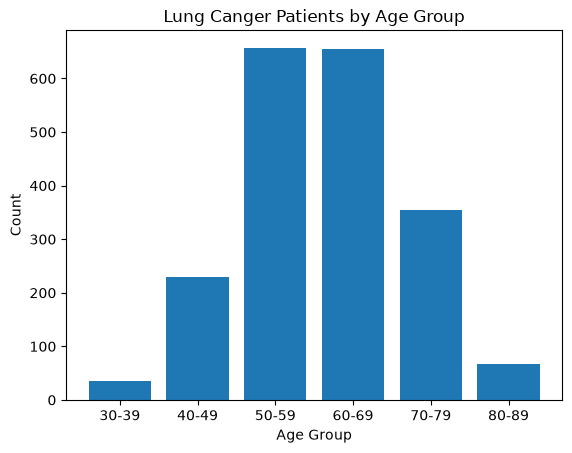

In [30]:
# Bar Chart (Age Groups)
age_order = ["30-39", "40-49", "50-59", "60-69", "70-79", "80-89"]

age_group_counts = get_category_count("Age_Group", patient_df)
age_group_counts_ordered = age_group_counts.reindex(age_order)

plt.bar(age_group_counts_ordered.index, 
        age_group_counts_ordered.values)
plt.title("Lung Canger Patients by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Count")
plt.show()

In [ ]:
# PATIENT COUNTS 
patient_df = df.filter(items=["Gender", "Age_Group", "Country", "Family_History"])
print(patient_df.head())

# count 
gender_count = patient_df["Gender"].value_counts(dropna=True)
print(gender_count)

age_count = patient_df["Age_Group"].value_counts(dropna=True)
# age_count_sorted = age_count.sort_values("Age_Group", ascending=True)
# print(age_count_sorted)
print(age_count)

country_count = patient_df["Country"].value_counts(dropna=True)
print(country_count)

fam_hist_count = patient_df["Family_History"].value_counts(dropna=True)
print(fam_hist_count)


In [4]:
# LIFESTYLE COUNTS
lifestyle_df = df.filter(items=["Smoking_Status", "Cigarettes_Per_Day", "Alcohol_Use", "Exercise_Frequency"])
print(lifestyle_df.head())

smoker_count = lifestyle_df["Smoking_Status"].value_counts(dropna=True)
print(smoker_count)

current_smokers = lifestyle_df["Smoking_Status"] == "Current Smoker"
avg_cigs = lifestyle_df.groupby("Smoking_Status")["Cigarettes_Per_Day"].mean()
print(avg_cigs)

alcohol_count = lifestyle_df["Alcohol_Use"].value_counts(dropna=True)
print(alcohol_count)

exercise_count = lifestyle_df["Exercise_Frequency"].value_counts(dropna=True)
print(exercise_count)


   Smoking_Status  Cigarettes_Per_Day Alcohol_Use Exercise_Frequency
0  Current Smoker                  28  No Alcohol                Low
1   Former Smoker                   5       Heavy           Moderate
2    Never Smoked                   0    Moderate                Low
3  Current Smoker                  21  No Alcohol                Low
4    Never Smoked                   0  No Alcohol                Low
Smoking_Status
Never Smoked      1311
Current Smoker     477
Former Smoker      212
Name: count, dtype: int64
Smoking_Status
Current Smoker    23.698113
Former Smoker     15.301887
Never Smoked       0.000000
Name: Cigarettes_Per_Day, dtype: float64
Alcohol_Use
Moderate      811
No Alcohol    786
Heavy         403
Name: count, dtype: int64
Exercise_Frequency
Low         772
Moderate    719
High        509
Name: count, dtype: int64


In [11]:
# ENVIRONMENTAL COUNTS 
environmental_df = df.filter(items=["WHO_Region", "Air_Pollution_Exposure", "Secondhand_Smoke"])
print(environmental_df.head())

africa = df[df["WHO_Region"] == "Africa"]
africa_env = africa.filter(items=["WHO_Region", "Country", "Air_Pollution_Exposure"])
print(africa_env.head())

americas = df[df["WHO_Region"] == "Americas"]
americas_env = americas.filter(items=["WHO_Region", "Country", "Air_Pollution_Exposure"])
print(americas_env.head())

east_med = df[df["WHO_Region"] == "Eastern Mediterranean"]
east_med_env = east_med.filter(items=["WHO_Region", "Country", "Air_Pollution_Exposure"])
print(east_med_env.head())

europe = df[df["WHO_Region"] == "Europe"]
europe_env = europe.filter(items=["WHO_Region", "Country", "Air_Pollution_Exposure"])
print(europe_env.head())

sea = df[df["WHO_Region"] == "South-East Asia"]
sea_env = sea.filter(items=["WHO_Region", "Country", "Air_Pollution_Exposure"])
print(sea_env.head())

west_pac = df[df["WHO_Region"] == "Western Pacific"]
west_pac_env = west_pac.filter(items=["WHO_Region", "Country", "Air_Pollution_Exposure"])
print(west_pac_env.head())




        WHO_Region Air_Pollution_Exposure Secondhand_Smoke
0  Western Pacific               Moderate              Yes
1         Americas                   High              Yes
2  Western Pacific                   High              Yes
3  Western Pacific               Moderate               No
4  Western Pacific                   High               No
   WHO_Region   Country Air_Pollution_Exposure
10     Africa   Nigeria                   High
50     Africa   Algeria               Moderate
62     Africa     Ghana                    Low
64     Africa  Ethiopia                   High
69     Africa   Morocco               Moderate
   WHO_Region    Country Air_Pollution_Exposure
1    Americas     Mexico                   High
24   Americas  Argentina                    Low
26   Americas   Colombia                    Low
27   Americas  Argentina                   High
29   Americas     Brazil                    Low
               WHO_Region  Country Air_Pollution_Exposure
5   Eastern Medite